# Figure 5

In [1]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_loo_comparison,
    load_ddm_posterior,
    load_ddm_subj_params,
    load_pupilbehavior_acceptmodel_historyeffect,
    load_pupilbehavior_acceptmodel_historyeffect_contrasts,
    DATASET_LABELS,
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
PUPIL_MODEL = "HDDM_Base_Lag1-stpdrift_Pupil"
FULL_MODEL = "HDDM_Base_Lag1-stpdrift_Pupil_stpdrift"

### Helper functions

In [2]:
HISTORYEFFECT_COLOR = "#55A868"
PUPIL_TERTILE_ORDER = ["Low", "Medium", "High"]
HISTORYEFFECT_BRACKET_SPECS = [
    ("Low", "Medium", "Medium - Low", 0),
    ("Medium", "High", "High - Medium", 0),
    ("Low", "High", "High - Low", 1),
]


def sig_stars(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "n.s."


def add_significance_bracket(ax, x1, x2, y, h, p):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color="black", linewidth=1.2)
    ax.text((x1 + x2) / 2, y + h, sig_stars(p), ha="center", va="bottom")


def plot_historyeffect_by_pupil_panel(ax, hist_df, contrasts_df, dataset,
                                      show_ylabel=False, show_xlabel=False):
    """Predicted P(accept) difference between a previous accept and a
    previous reject (the choice-history effect), evaluated at the Low/
    Medium/High pupil tertiles -- pupil stays continuous in the underlying
    model, this only plots avg_comparisons() evaluated at 3 representative
    values (see analysis_pupilbehavior/1_pupilbehavior_acceptmodel.R)."""
    ds_hist = (hist_df[hist_df["dataset"] == dataset]
              .set_index("pupil_tertile").loc[PUPIL_TERTILE_ORDER])
    ds_contrasts = contrasts_df[contrasts_df["dataset"] == dataset]

    x_pos = np.arange(len(PUPIL_TERTILE_ORDER))
    means = ds_hist["historyeffect"].values
    los = ds_hist["asymp.LCL"].values
    his = ds_hist["asymp.UCL"].values
    yerr = [means - los, his - means]

    ax.errorbar(x_pos, means, yerr=yerr, fmt="o", color=HISTORYEFFECT_COLOR,
               markersize=14, ecolor=HISTORYEFFECT_COLOR, elinewidth=2,
               capsize=6, zorder=3)
    ax.axhline(0, color="#aaaaaa", linewidth=1, linestyle="--", zorder=1)

    y_top, y_bottom = his.max(), min(los.min(), 0)
    y_range = y_top - y_bottom
    bracket_h = 0.02 * y_range
    tier_gap = 0.15
    for label_a, label_b, contrast_name, tier in HISTORYEFFECT_BRACKET_SPECS:
        p_val = ds_contrasts.loc[ds_contrasts["contrast"] == contrast_name, "p_adj_bh"].iloc[0]
        x1, x2 = x_pos[PUPIL_TERTILE_ORDER.index(label_a)], x_pos[PUPIL_TERTILE_ORDER.index(label_b)]
        y_bracket = y_top + (0.08 + tier_gap * tier) * y_range
        add_significance_bracket(ax, x1, x2, y_bracket, bracket_h, p_val)

    max_tier = max(tier for _, _, _, tier in HISTORYEFFECT_BRACKET_SPECS)
    ax.set_ylim(y_bottom - 0.05 * y_range, y_top + (0.08 + tier_gap * max_tier + 0.15) * y_range)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(PUPIL_TERTILE_ORDER)
    ax.set_xlim(-0.5, len(PUPIL_TERTILE_ORDER) - 0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_title(DATASET_LABELS.get(dataset, dataset))
    if show_ylabel:
        ax.set_ylabel("Choice-History Effect\non P(accept)")
    if show_xlabel:
        ax.set_xlabel("Pupil Tertile")


BAR_COLOR = "#4C72B0"

ELPD_MODEL_ORDER = [
    ("HDDM_Base_Lag1-stpdrift_Pupil_stp",      "Pupil ->\nStp-CH"),
    ("HDDM_Base_Lag1-stpdrift_Pupil_drift",    "Pupil ->\nDrift-CH"),
    ("HDDM_Base_Lag1-stpdrift_Pupil_stpdrift", "Pupil ->\nStp-Drift-CH"),
]


def plot_elpd_improvement_panel(ax, dataset, show_ylabel=False):
    """Bars: elpd_loo(variant) - elpd_loo(PUPIL_MODEL) for each mechanism
    variant, i.e. how much better each pupil-modulation model fits than the
    plain Pupil model. No error bars -- the LOO table's own `dse` is the SE
    relative to whichever model ranks best, not specifically to PUPIL_MODEL
    (see figure3.ipynb's equivalent draft cell for the same reasoning)."""
    loo = load_loo_comparison(dataset, group_name="mechanisms_arousal").set_index("model")["elpd_loo"]
    baseline_elpd = loo[PUPIL_MODEL]
    diffs = [loo[m] - baseline_elpd for m, _ in ELPD_MODEL_ORDER]

    x_pos = np.arange(len(ELPD_MODEL_ORDER))
    ax.bar(x_pos, diffs, color=BAR_COLOR, width=0.6, zorder=3)
    ax.axhline(0, color="black", linestyle="--", linewidth=1.5, zorder=2)

    ax.set_xticks(x_pos)
    ax.set_xticklabels([label for _, label in ELPD_MODEL_ORDER])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_title(DATASET_LABELS.get(dataset, dataset))
    if show_ylabel:
        ax.set_ylabel("ELPD improvement\nover Pupil model")


def group_samples(posterior, param):
    return np.asarray(posterior[param]).flatten()


def plot_posterior_histogram_panel(ax, samples, color, show_ylabel=False,
                                   xlabel=None, ylabel_text=None):
    """Group-level posterior sample histogram for one DDM parameter, with a
    dashed reference line at 0 (the no-effect null)."""
    ax.hist(samples, bins=60, color=color, alpha=0.55, linewidth=0.8, density=False)
    ax.hist(samples, bins=60, histtype="step", color="black", linewidth=1.5)
    ax.axvline(0, color="black", linestyle="--", linewidth=1.5, zorder=4)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if show_ylabel:
        ax.set_ylabel(f"{ylabel_text}\nSample Counts")
    if xlabel:
        ax.set_xlabel(f"{xlabel}\n")

### 4x3 figure: choice-history-by-pupil, ELPD improvement, and pupil-modulation posteriors
Columns = datasets. Row A: predicted P(accept) difference between a previous
accept and a previous reject (the choice-history effect), evaluated at the
Low/Medium/High pupil tertiles from the accept model's
`choice_prev1 * pupil` interaction (`analysis_pupilbehavior/1_pupilbehavior_acceptmodel.R`).
Row B: `elpd_loo` improvement of each pupil-modulation mechanism variant
over the plain Pupil model. Row C: group-level posterior of
`z_choice_prev1:pupil` (pupil modulation of the starting-point bias), from
the full Stp-Drift-CH model. Row D: group-level posterior of
`v_choice_prev1:pupil` (pupil modulation of the drift bias), same model.

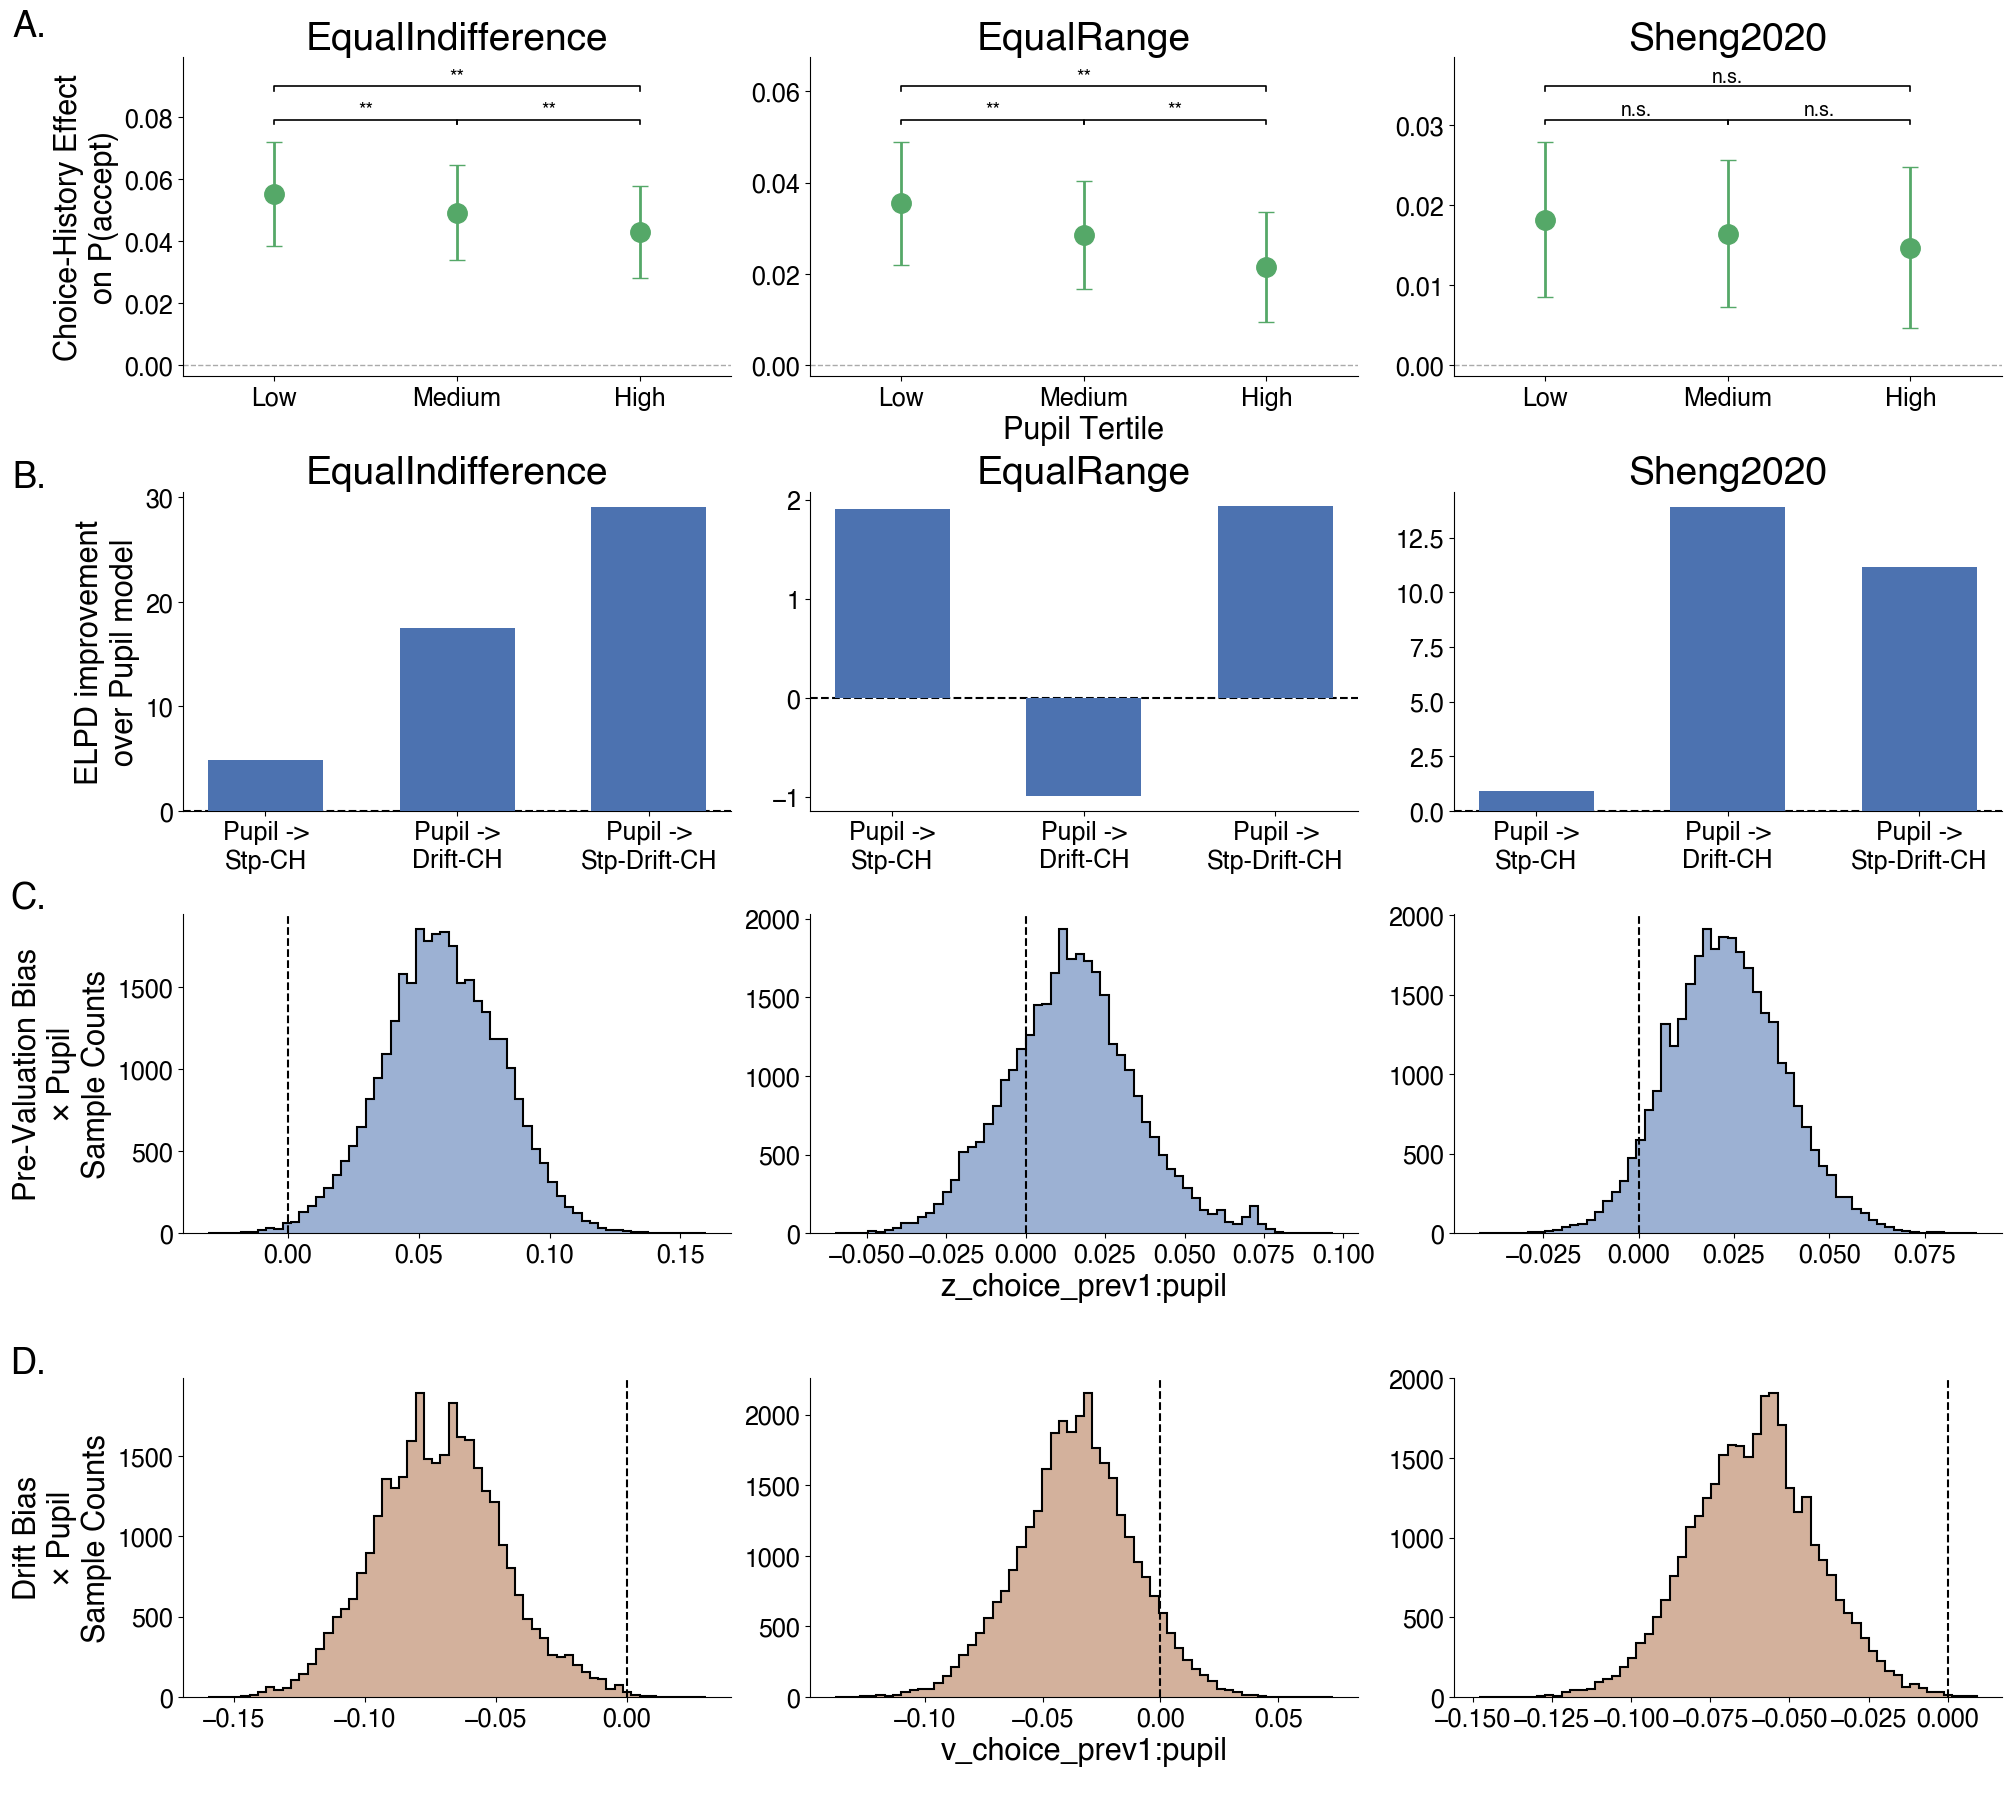

In [3]:
Z_HIST_COLOR = "#4C72B0"
V_HIST_COLOR = "#B0724C"

posteriors = {ds: load_ddm_posterior(FULL_MODEL, ds) for ds in DATASETS}
historyeffect_df = load_pupilbehavior_acceptmodel_historyeffect()
historyeffect_contrasts_df = load_pupilbehavior_acceptmodel_historyeffect_contrasts()

fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(20, 18), layout="constrained")

# --- Row A: choice-history effect (prev accept - prev reject) by pupil tertile ---
for col, ds in enumerate(DATASETS):
    plot_historyeffect_by_pupil_panel(
        axes[0, col], historyeffect_df, historyeffect_contrasts_df, ds,
        show_ylabel=(col == 0), show_xlabel=(col == 1),
    )

# --- Row B: ELPD improvement over the Pupil model ---
for col, ds in enumerate(DATASETS):
    plot_elpd_improvement_panel(axes[1, col], ds, show_ylabel=(col == 0))

# --- Row C: z_choice_prev1:pupil posterior ---
for col, ds in enumerate(DATASETS):
    samples = group_samples(posteriors[ds], "z_choice_prev1:pupil")
    plot_posterior_histogram_panel(
        axes[2, col], samples, Z_HIST_COLOR, show_ylabel=(col == 0),
        xlabel="z_choice_prev1:pupil" if col == 1 else None,
        ylabel_text="Pre-Valuation Bias\n× Pupil",
    )

# --- Row D: v_choice_prev1:pupil posterior ---
for col, ds in enumerate(DATASETS):
    samples = group_samples(posteriors[ds], "v_choice_prev1:pupil")
    plot_posterior_histogram_panel(
        axes[3, col], samples, V_HIST_COLOR, show_ylabel=(col == 0),
        xlabel="v_choice_prev1:pupil" if col == 1 else None,
        ylabel_text="Drift Bias\n× Pupil",
    )

# Row labels, placed just outside the top-left corner of each row's
# leftmost panel (same convention as figure1.ipynb's "A."/"B."/"C.")
axes[0, 0].text(-0.25, 1.15, "A.", transform=axes[0, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
axes[1, 0].text(-0.25, 1.1, "B.", transform=axes[1, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
axes[2, 0].text(-0.25, 1.1, "C.", transform=axes[2, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
axes[3, 0].text(-0.25, 1.1, "D.", transform=axes[3, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")

fig.savefig("saved/figure5.svg", dpi=300, bbox_inches="tight")
plt.show()

### Correlation between the pupil-modulation subject params
Per-subject point estimates (`param_value`, `.../hddm_params/{FULL_MODEL}_{dataset}_subj_params.csv`) for `z_pupil`, `z_choice_prev1:pupil`, `v_pupil`, `v_choice_prev1:pupil` -- pairwise Pearson correlation, one matrix per dataset.

In [4]:
PUPIL_PARAMS = ["z_pupil", "z_choice_prev1:pupil", "v_pupil", "v_choice_prev1:pupil"]

for ds in DATASETS:
    subj_params = load_ddm_subj_params(FULL_MODEL, ds)
    wide = (
        subj_params[subj_params["param_name"].isin(PUPIL_PARAMS)]
        .pivot(index="sub", columns="param_name", values="param_value")[PUPIL_PARAMS]
    )
    print(f"\n{ds}")
    print(wide.corr())


equalIndifference
param_name             z_pupil  z_choice_prev1:pupil   v_pupil  \
param_name                                                       
z_pupil               1.000000              0.461466 -0.165835   
z_choice_prev1:pupil  0.461466              1.000000 -0.098386   
v_pupil              -0.165835             -0.098386  1.000000   
v_choice_prev1:pupil  0.031030              0.152341  0.200496   

param_name            v_choice_prev1:pupil  
param_name                                  
z_pupil                           0.031030  
z_choice_prev1:pupil              0.152341  
v_pupil                           0.200496  
v_choice_prev1:pupil              1.000000  

equalRange
param_name             z_pupil  z_choice_prev1:pupil   v_pupil  \
param_name                                                       
z_pupil               1.000000             -0.016408  0.038970   
z_choice_prev1:pupil -0.016408              1.000000  0.114855   
v_pupil               0.038970        

In [3]:
s = pd.read_csv("/Users/gustxsr/Documents/Stanford/PoldrackLab/github/riskhistory/results/analysis_pupilbehavior/2_pupilbehavior_rtmodel_contrasts.csv")

In [5]:
s["pupil"] = ["Low", "Low", "Medium", "Medium", "High", "High"]*3

In [8]:
s["c"] = ["AR-RR", "RA-AA"]*9

<Axes: xlabel='pupil', ylabel='rt_diff'>

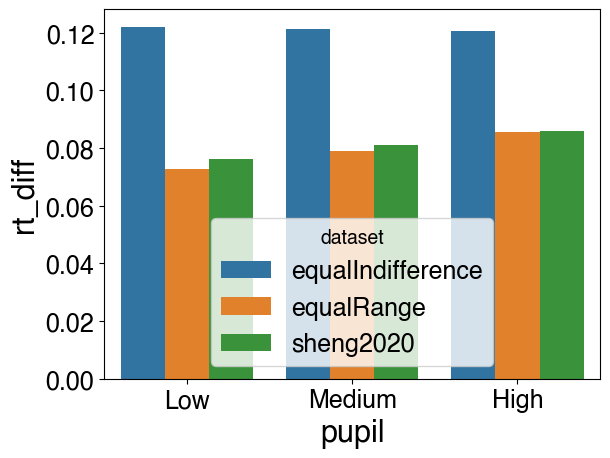

In [11]:
import seaborn as sns
sns.barplot(s.query("c == 'RA-AA'"), x = "pupil", y = "rt_diff", hue = "dataset")

<Axes: xlabel='pupil', ylabel='rt_diff'>

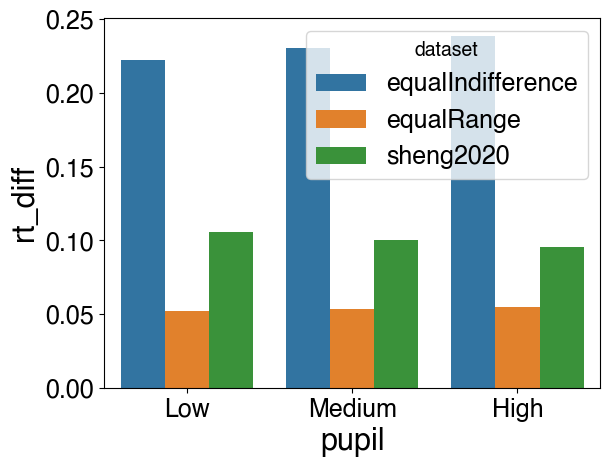

In [12]:
sns.barplot(s.query("c == 'AR-RR'"), x = "pupil", y = "rt_diff", hue = "dataset")